Pehle ek zaroori baat: RMSE ek regression metric hai. Wo “number” predict karne wale models naapta hai, jaise “agle 90 din mein customer kitna spend karega”. Tumhara churn model (0/1) classification hai, isliye uspar RMSE nahi lagta. Churn model ke metrics Precision, Recall, F1 aur AUC hi rahenge. Aaj ek chhota side-exercise karenge: apne hi data se ek regression target banayenge (future 90-din ka spend), taaki RMSE ko asli data par samajh sako. Yeh Day 82 ke CLV ka bhi preview hai.

RMSE kya hai:

RMSE = √( mean( (actual − predicted)² ) )

- Har galti ko square karte hain, to badi galtiyan bahut zyada penalize hoti hain.
- Phir sqrt lete hain, taaki answer target ki same unit (£) mein aaye.
- Chhota RMSE behtar hai. Isse hamesha baseline se compare karo, akele number ka matlab nahi hota.

Aaj ka rule: Model compare CV par hoga. Test set par sirf ek baar final number nikalna hai.

1. Setup:

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.compose import TransformedTargetRegressor

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

2. RMSE ko hath se samjho (4 customers ka chhota example):

In [15]:
actual    = np.array([100, 200, 300, 400])
predicted = np.array([110, 190, 330, 300])

err = predicted - actual
print("Errors         :", err)                       # [10, -10, 30, -100]
print("Squared errors :", err ** 2)
print("MAE            :", np.abs(err).mean())
print("RMSE (manual)  :", np.sqrt((err ** 2).mean()))
print("RMSE (sklearn) :", rmse(actual, predicted))

Errors         : [  10  -10   30 -100]
Squared errors : [  100   100   900 10000]
MAE            : 37.5
RMSE (manual)  : 52.67826876426369
RMSE (sklearn) : 52.67826876426369


Dhyan do: MAE 37.5 aata hai, lekin RMSE ~ 53.4. Ek badi galti (−100) ne RMSE ko kheench diya. Yahi RMSE ki khaasiyat (aur kamzori) hai: RMSE ≥ MAE hamesha, aur dono ka gap batata hai ki galtiyan kitni “unequal” hain.

3. Churn dataset se future-spend target banao (leakage-free, Day 62 wala cutoff):

In [16]:
tx = pd.read_csv(
    '../../data/processed/step4_datatypes_fixed.csv',
    dtype={'Invoice': str, 'StockCode': str},
    parse_dates=['InvoiceDate'],
    usecols=['Invoice', 'InvoiceDate', 'Quantity', 'Price', 'Customer ID']
)
tx['LineTotal'] = tx['Quantity'] * tx['Price']

cutoff = tx['InvoiceDate'].max() - pd.Timedelta(days=90)
future_spend = tx[tx['InvoiceDate'] >= cutoff].groupby('Customer ID')['LineTotal'].sum()

features = pd.read_csv('../../data/processed/customer_ml_dataset.csv')
features['FutureSpend'] = features['Customer ID'].map(future_spend).fillna(0)

print(pd.crosstab(features['Churned'], features['FutureSpend'] > 0))

FutureSpend  False  True 
Churned                  
0                0   2292
1             2991      0


Features sirf cutoff se pehle ke behaviour se bane hain, target cutoff ke baad ka hai. Crosstab mein dikhna chahiye ki Churned=1 wale customers ka future spend 0 hai. Yeh sanity check hai ki target aur churn label ek hi timeline par hain.

4. Wahi train/test split dobara banao (taaki customers same rahein):

In [17]:
cols = ['Recency', 'Frequency', 'Monetary_log', 'AvgOrderValue', 'Tenure', 'UniqueProducts', 'Region']
X = pd.get_dummies(features[cols], columns=['Region'], drop_first=True)

idx_tr, idx_te = train_test_split(features.index, test_size=0.2, random_state=42, stratify=features['Churned'])

X_tr, X_te = X.loc[idx_tr], X.loc[idx_te]
y_tr, y_te = features.loc[idx_tr, 'FutureSpend'], features.loc[idx_te, 'FutureSpend']

X_test_saved = pd.read_csv('../../data/processed/X_test.csv')
print("Split Day 63 jaisa hi hai:", np.allclose(X_te.astype(float).values, X_test_saved.astype(float).values))

Split Day 63 jaisa hi hai: True


Yeh True aana chahiye. Agar False aaye to Day 62-63 ka kuch step alag tha, pehle usse theek karo.

5. Target ka haal dekho (regression ke liye yeh sabse zaroori step hai):

count      4226.00
mean        562.42
std        4023.01
min           0.00
25%           0.00
50%           0.00
75%         437.14
max      168469.60
Name: FutureSpend, dtype: float64
Zero-spend customers: 56.6%
Skewness: 30.10


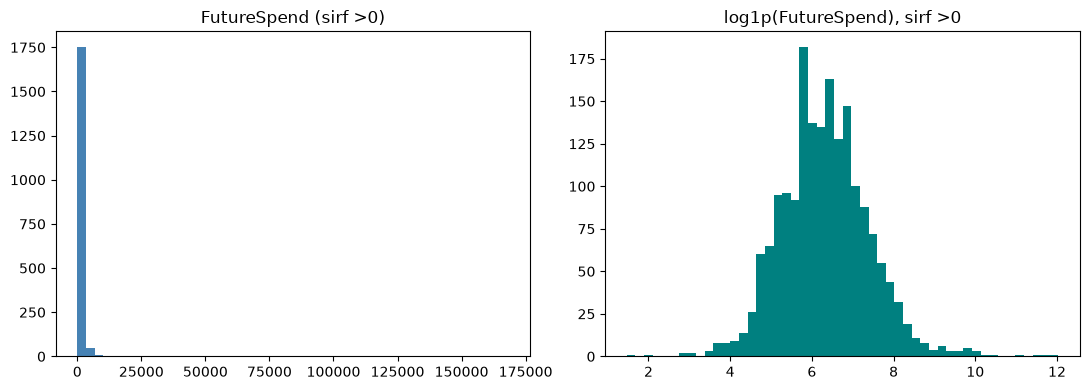

In [18]:
print(y_tr.describe().round(2))
print(f"Zero-spend customers: {(y_tr == 0).mean():.1%}")
print(f"Skewness: {y_tr.skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(y_tr[y_tr > 0], bins=50, color='steelblue')
axes[0].set_title('FutureSpend (sirf >0)')
axes[1].hist(np.log1p(y_tr[y_tr > 0]), bins=50, color='teal')
axes[1].set_title('log1p(FutureSpend), sirf >0')
plt.tight_layout()
plt.show()

Yeh target zero-heavy aur bahut right-skewed hoga (Day 42 jaisa). Aise target par RMSE kuch “whale” customers se dominate hota hai. Yeh dhyan mein rakho.

6. Baseline pehle (hamesha):

In [19]:
mean_base = DummyRegressor(strategy='mean').fit(X_tr, y_tr)
med_base = DummyRegressor(strategy='median').fit(X_tr, y_tr)

for name, b in [('Hamesha mean predict', mean_base), ('Hamesha median predict', med_base)]:
    p = b.predict(X_te)
    print(f"{name}: RMSE {rmse(y_te, p):.1f} | MAE {mean_absolute_error(y_te, p):.1f} | R2 {r2_score(y_te, p):.3f}")

print(f"\nTest target ka std: {y_te.std(ddof=0):.1f}")

Hamesha mean predict: RMSE 4003.9 | MAE 831.7 | R2 -0.000
Hamesha median predict: RMSE 4052.5 | MAE 628.7 | R2 -0.025

Test target ka std: 4003.4


main topic:

- Mean predict karne wale baseline ka RMSE lagbhag target ke std ke barabar aata hai. Yehi “kuch nahi seekha” ka score hai.
- Median baseline ka MAE kam, lekin RMSE zyada aa sakta hai. Matlab metric chunne se “best” ka jawab badal jaata hai.
- R² = 1 − MSE/Variance. Mean baseline ka R² lagbhag 0 hota hai. Agar tumhara model R² ≈ 0.3 deta hai, to wo variance ka 30% explain karta hai.

7. Do models CV par (KFold, kyunki target continuous hai, stratify nahi):

In [20]:
num_cols = ['Recency', 'Frequency', 'Monetary_log', 'AvgOrderValue', 'Tenure', 'UniqueProducts']
prep = ColumnTransformer([('scale', StandardScaler(), num_cols)], remainder='passthrough')

reg_models = {
    'Linear Regression': Pipeline([('prep', prep), ('model', LinearRegression())]),
    'Decision Tree Reg (depth 4)': DecisionTreeRegressor(max_depth=4, min_samples_leaf=50, random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

rows = []
for name, m in {**reg_models, 'Baseline (mean)': DummyRegressor(strategy='mean')}.items():
    r = cross_validate(m, X_tr, y_tr, cv=kf, scoring=scoring, return_train_score=True)
    rows.append({'model': name,
                 'train RMSE': -r['train_rmse'].mean(),
                 'CV RMSE': -r['test_rmse'].mean(),
                 'CV RMSE std': r['test_rmse'].std(),
                 'CV MAE': -r['test_mae'].mean(),
                 'CV R2': r['test_r2'].mean()})
cv_table = pd.DataFrame(rows).set_index('model').round(2)
print(cv_table)

                             train RMSE  CV RMSE  CV RMSE std  CV MAE  CV R2
model                                                                       
Linear Regression               3745.13  3513.46      1651.22  655.75   0.01
Decision Tree Reg (depth 4)     3752.69  3389.44      1806.48  624.90   0.14
Baseline (mean)                 4002.54  3613.60      1769.88  760.14  -0.01


Kaise padho: CV RMSE ko baseline se compare karo, train aur CV ka gap dekho (overfitting), aur CV RMSE std se dekho ki fold-to-fold number kitna hilta hai.

8. Log-target trick (skewed target ke liye common approach):

In [21]:
log_lr = TransformedTargetRegressor(
    regressor=Pipeline([('prep', prep), ('model', LinearRegression())]),
    func=np.log1p, inverse_func=np.expm1
)

r = cross_validate(log_lr, X_tr, y_tr, cv=kf, scoring=scoring)
print(f"LinearReg on log1p(target): CV RMSE in £ = {-r['test_rmse'].mean():.1f}, MAE = {-r['test_mae'].mean():.1f}")

LinearReg on log1p(target): CV RMSE in £ = 3634387.5, MAE = 125624.6


Yeh model log-scale par seekhta hai, par RMSE tum asli £ mein naapte ho. Aksar MAE behtar hota hai (aam customers par achha), lekin RMSE badh sakta hai, kyunki log-model whales ka spend underestimate karta hai aur RMSE un badi galtiyon ko bahut punish karta hai. Dono result dekh kar tay karo ki business ko kya chahiye.

9. RMSE kitna “whales” se chalta hai:

In [22]:
best = reg_models['Linear Regression'].fit(X_tr, y_tr)
pred = np.clip(best.predict(X_te), 0, None)          # spend negative nahi ho sakta

cut = y_te.quantile(0.99)
mask = (y_te <= cut).values

print(f"RMSE (sab customers)        : {rmse(y_te, pred):.1f}")
print(f"RMSE (top 1% spenders hata ke): {rmse(y_te[mask], pred[mask]):.1f}")
print(f"MAE  (sab customers)        : {mean_absolute_error(y_te, pred):.1f}")

RMSE (sab customers)        : 2987.4
RMSE (top 1% spenders hata ke): 955.6
MAE  (sab customers)        : 594.0


Agar top 1% hatane par RMSE bahut gir jaata hai, to RMSE ka bada hissa sirf kuch customers ki wajah se hai. Isi liye Month 3 ke outlier lessons (Day 48-49) regression mein bhi kaam aate hain.

10. Residual analysis (RMSE ke peeche kya chal raha hai):

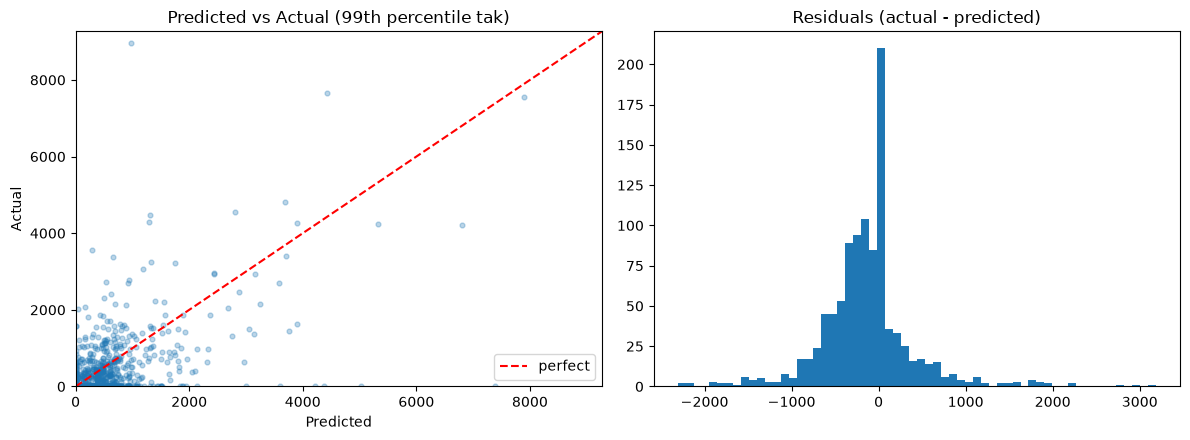

In [23]:
resid = y_te.values - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(pred, y_te, alpha=0.3, s=12)
lim = np.percentile(y_te, 99)
axes[0].plot([0, lim], [0, lim], 'r--', label='perfect')
axes[0].set_xlim(0, lim); axes[0].set_ylim(0, lim)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
axes[0].set_title('Predicted vs Actual (99th percentile tak)')
axes[0].legend()

axes[1].hist(resid, bins=60, range=(np.percentile(resid, 1), np.percentile(resid, 99)))
axes[1].set_title('Residuals (actual - predicted)')
plt.tight_layout()
plt.show()

Jo points diagonal se door hain, wahi RMSE ko badhate hain. Residuals ka histogram symmetric aur 0 ke paas hona chahiye, warna model kisi taraf systematically galat hai.

11. Test par final score (sirf ek baar):

In [24]:
base_p = mean_base.predict(X_te)
test_rmse, base_rmse = rmse(y_te, pred), rmse(y_te, base_p)

print(f"Baseline RMSE : {base_rmse:.1f}")
print(f"Model RMSE    : {test_rmse:.1f}")
print(f"Improvement   : {(1 - test_rmse / base_rmse):.1%}")
print(f"Model MAE     : {mean_absolute_error(y_te, pred):.1f}")
print(f"Model R2      : {r2_score(y_te, pred):.3f}")

Baseline RMSE : 4003.9
Model RMSE    : 2987.4
Improvement   : 25.4%
Model MAE     : 594.0
Model R2      : 0.443


Test RMSE aur CV RMSE paas hone chahiye. Is number ko dekh kar model mat badlo.

12. RMSE vs MAE kab kaunsa:

In [25]:
print("""
RMSE: badi galtiyon ko zyada saza deta hai, jab ek badi miss bahut mehngi ho (jaise bade customer ka spend galat predict karna).
MAE : aam galti ka seedha average, outliers se kam hilta hai.
R2  : baseline ke mukable kitna behtar (0 = mean jitna, 1 = perfect).
RMSLE: log-scale par error, jab percentage jaisi galti matter kare aur target heavy-tailed ho.
""")


RMSE: badi galtiyon ko zyada saza deta hai, jab ek badi miss bahut mehngi ho (jaise bade customer ka spend galat predict karna).
MAE : aam galti ka seedha average, outliers se kam hilta hai.
R2  : baseline ke mukable kitna behtar (0 = mean jitna, 1 = perfect).
RMSLE: log-scale par error, jab percentage jaisi galti matter kare aur target heavy-tailed ho.



13. Churn project se connection (concept, jo Day 82 mein kaam aayega):

In [26]:
print("""
Customer ki value ek hurdle ki tarah soch sakte ho:
  expected future spend = P(customer wapas aayega) x (wapas aane par kitna spend karega)
Pehla part tumhara churn classifier deta hai (probability). Dusra part ek regression model deta hai.
RMSE isi dusre part ko naapne ke kaam aata hai. Isko Day 82 ke CLV mein dekhenge.
""")


Customer ki value ek hurdle ki tarah soch sakte ho:
  expected future spend = P(customer wapas aayega) x (wapas aane par kitna spend karega)
Pehla part tumhara churn classifier deta hai (probability). Dusra part ek regression model deta hai.
RMSE isi dusre part ko naapne ke kaam aata hai. Isko Day 82 ke CLV mein dekhenge.



practice questions:

1. Sirf un customers par RMSE nikaalo jinka FutureSpend > 0 hai (yaani jo wapas aaye). Model ka RMSE aur baseline ka RMSE alag-alag dekho. Zero-spend customers ke saath aur bina inke result kaise badalta hai?

2. max_depth ko 2, 4, 8, 12 karke Decision Tree Regressor ka CV RMSE nikaalo. Day 69 ka same overfitting pattern (train RMSE girta hai, CV RMSE ruk jaata hai ya badhta hai) yahan bhi dikhta hai?

3. Apne shabdon mein likho: ek manager ko samjhao ki “RMSE £X hai” ka kya matlab hai, aur yeh akela number kab bhramak ho sakta hai.

rough work


ek problem jo humhare repo mein hone ki bahut sambhavna hai: do alag churn definitions. Purani wali (Day 35B) poore period par bani thi, aur nayi (Day 62) future window par. EDA notebooks mein churn rate ek aur ML section mein alag hoga. Agar README mein dono ka fark samjhaya nahi, to interviewer ko lagega tum numbers galat likh rahe ho. Check karo:

In [27]:
import pandas as pd

old = pd.read_csv('../../data/processed/customer_churn_labeled.csv')   # Day 35B (EDA ke liye)
new = pd.read_csv('../../data/processed/customer_ml_dataset.csv')      # Day 62 (ML ke liye)

print("EDA label : churn %", round(old['Churned'].mean() * 100, 1), "| customers", len(old))
print("ML label  : churn %", round(new['Churned'].mean() * 100, 1), "| customers", len(new))

y_te = pd.read_csv('../../data/processed/y_test.csv').squeeze()
print("Test set  : customers", len(y_te), "| churners", int(y_te.sum()))

EDA label : churn % 50.8 | customers 5881
ML label  : churn % 56.6 | customers 5283
Test set  : customers 1057 | churners 598


Customers ki sankhya alag aa sakti hai, aur wo theek hai. ML dataset sirf unhe rakhta hai jinhone cutoff se pehle kuch kharida tha. Ye difference README ke “Target Variable” section mein ek line mein likhna zaroori hai:

“EDA uses a descriptive Recency-based label over the full period. The ML models use a separate leakage-free label (features before the cutoff, outcome in the 90 days after), so the two churn rates differ by design.”

Ab har number ko README se piche trace karo. Teen numbers chuno (churn rate, best model ka test F1, precision@10%) aur har ek ke liye likho: README ka number → kaunsa notebook → kaunsa cell → kaunsi file. Agar koi number tum trace nahi kar paye, to wo number galat ho sakta hai ya README mein guess likha hai.

ROUGH WORK

In [28]:
import sys
import os

# Project root folder ka path add karein (kyunki notebook 2 level andar hai)
sys.path.append(os.path.abspath(os.path.join('../..')))

# Ab isko import karein
from src.models.evaluate import evaluation_table

print("Successfully imported!")

Successfully imported!


In [29]:
from src.models.evaluate import evaluation_table